**Link to GitHub-repo:** https://github.com/eliashollstrand/melody-similarity

# Setup

In [1]:
from pathlib import Path
import subprocess

REPO = Path("/content/repo")

if not REPO.exists():
    subprocess.run(
        ["git", "clone",
         "https://github.com/eliashollstrand/melody-similarity.git",
         str(REPO)],
        check=True,
    )
else:
    subprocess.run(
        ["git", "-C", str(REPO), "pull", "--ff-only"],
        check=True,
    )

RESULTS = REPO / "results"

ap_files = sorted(RESULTS.rglob("*_ap.csv"))
#print(f"Found {len(ap_files)} AP files")
#print("\n".join(str(p.relative_to(RESULTS)) for p in ap_files))

# Comparing Melodic Similarity Methods

## 1. Introduction and data

To determine the similarity between two melodies is an important but challenging problem in music information retrieval. It is relevant to applications such as plagiarism detection, music recommendation and version identification. Unlike exact note to note comparison we as humans have the ability to recognize that two melodies are related even though they might be preformed in different keys or tempos, with different rhythms or if some notes have been altered. A computational similarity method must therefore decide which musical characteristics are essential and which differences can be disregarded.

This project investigates how different melody representations and distance measures affect the computational assessment of melodic similarity. Three representations are considered: absolute MIDI pitch, intervals between consecutive notes and melodic contour describing whether the melody moves downward, upward or if it remains on the same pitch. Each of these representations are evaluated both with and without information about note duration. The resulting sequences are evaluated using edit distance, dynamic time warping and n-gram overlapping combining for 18 handcrafted similarity methods. Their performance is also compared with CLaMP 2 which is a pretrained model for symbolic music representation using cosine similarity between its melody embeddings.

This experiment uses the Meertens Tune Collections Annotated Corpus (MTC-ANN 2.0.1). It is a dataset containing 360 monophonic Dutch folk song melodies grouped by experts into 26 tune families. Melodies that belong to the same tune family are understood to be variants of an underlying tune despite possible shiftings in pitch, different rhythms, structures and so on. These expert labels provide a suitable ground truth for evaluating whether a computational method captures musically meaningful similarity. Each melody was provided as a MIDI file, identified by a unique song ID and the corresponding tune family.

In the experiment each melody is used as a query and compared with every other melody in the dataset, the remaining melodies are ranked according to their calculated similarity and melodies belonging to the same tune family as the query are treated as relevant results. The performance is measured using mean average precision (MAP) which reflects how consistently relevant melodies appear near the top of the rankings. The projects aim is to determine which combination of representation and distance measure best reproduce these expert defined tune families and to examine how these traditional approaches compare with a pretrained music model.

## 2. Method

### 2.1 Representations

Before two melodies can be compared, they have to be turned into sequences. The choice of representation decides what a distance measure can distinguish, i.e. a measure applied to intervals cannot tell a melody from its transposition, and a measure working on contour cannot tell a small step from a large one. Choosing a way to represent melodies is therefore a choice about which differences between two melodies should be taken into account and which should be ignored.

The loader (`src/data_loading.py`) gives every melody asa list of notes `(onset, duration, pitch)`, with onset and duration in quarter notes and pitch as a MIDI note number. The representations are implemented in `src/representations.py`. As a running example we use the opening of *Twinkle Twinkle Little Star* (C C G G A A G):

In [2]:
import sys
sys.path.append(str(REPO / "src"))

from representations import pitch, interval, contour, add_durations, build_representations

twinkle = [(0, 1, 60), (1, 1, 60), (2, 1, 67), (3, 1, 67), (4, 1, 69), (5, 1, 69), (6, 2, 67)]

print("pitch:   ", pitch(twinkle))
print("interval:", interval(twinkle))
print("contour: ", contour(twinkle))

pitch:    [60, 60, 67, 67, 69, 69, 67]
interval: [0, 7, 0, 2, 0, -2]
contour:  [0, 1, 0, 1, 0, -1]


Each representation disregards more information that the one before:

- **Pitch** keeps everything, including the key. The same song played a tone higher gives a completely different sequence.
- **Interval** only keeps the steps between notes, so the melody gives the same sequence in any key. This matters for MTC-ANN, where variants of a tune can be notated in different keys.
- **Contour** also disregards the size of each step. Thus, it is robust to a musician hitting slightly different notes here and there, however, it is very coarse. With only three symbols, unrelated melodies can quite easily share long stretches of contour.

Intervals and contour representations are both one element shorter than for pitch, since they describe the steps *between* notes. Transposing `twinkle` up a whole step shows the difference in robustness to transposition:

In [3]:
twinkle_in_D = [(_, _, pitch + 2) for _, _, pitch in twinkle]

print("pitch:   ", pitch(twinkle_in_D))
print("interval:", interval(twinkle_in_D))
print("contour: ", contour(twinkle_in_D))

pitch:    [62, 62, 69, 69, 71, 71, 69]
interval: [0, 7, 0, 2, 0, -2]
contour:  [0, 1, 0, 1, 0, -1]


#### 2.1.1 With and without durations

Each representation also exists with durations(`pitch+dur`, `interval+dur`, `contour+dur`). Every element then becomes a tuple `(value, duration)`. For pitch, each note gets its own duration. For interval and contour, each step is paired with the duration of the note it arrives on, and the first note's duration is dropped so that the values and durations line up:

In [4]:
print("pitch+dur:   ", add_durations(pitch(twinkle), twinkle))
print("interval+dur:", add_durations(interval(twinkle), twinkle))
print("contour+dur: ", add_durations(contour(twinkle), twinkle))

pitch+dur:    [(60, 1), (60, 1), (67, 1), (67, 1), (69, 1), (69, 1), (67, 2)]
interval+dur: [(0, 1), (7, 1), (0, 1), (2, 1), (0, 1), (-2, 2)]
contour+dur:  [(0, 1), (1, 1), (0, 1), (1, 1), (0, 1), (-1, 2)]


Durations are the notated length of each note in quarter notes, so the tempo of the MIDI file does not matter. Furthermore, rests are not represented, i.e. a note followed by a rest has the same duration as one that is not.

`build_representations(melodies)` applies all of this to the whole dataset and returns one dictionary per representation, `{representaion: {songid: sequence}}`. The six representations combined with the three distance measures below give the 18 hand-crafted methods.

#### 2.1.2 What we expected

There is a trade-off between which differences matter and which do not matter, and thus, which should be kept. We expected intervals to work best, since they ignore the key but keep the shape of the melody, pitch to suffer from transposed variants, and contour to suffer from lack of detailed information. Durations could either help, since rhythm is an important part of a tune's identity, or they could hurt, due to variants of the same tune differing in rhythm.

### 2.2 Distance measures

Given two melodies as sequences, a distance measure gives a single number for how different they are. We implemented three classic measures in `src/distances.py` that look at different things:

- **Edit distance** counts the changes needed to turn one melody into the other
- **Dynamic time warping (DTW)** measures how far apart the notes are after the best possible stretching and alignment of two melodies
- **N-gram overlap** counts shared short fragments, regardless of where in the melody they occur.

All three of these are then turned into similiaries (higher = more similar), so that every method, including CLaMP 2, produces the same kind of N × N matrix. For the evaluation only the *ranking* of the melodies matter, so the exact scale of each similarity is not important.

As a running example we use `twinkle`'s intervals (`A`) and two variants of it: one where the last step is changed (`B`), and one with an extra repeated note (`C`):

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from distances import (edit_distance, edit_similarity, cost_matrix, accumulated_cost,
                       optimal_path, dtw_distance, dtw_similarity, ngrams, ngram_similarity)


A = [0, 7, 0, 2, 0, -2]       # twinkle
B = [0, 7, 0, 2, 0, -4]       # last step changed
C = [0, 7, 0, 0, 2, 0, -2]    # one extra repeated note

#### 2.2.1 Edit distance

The edit (Levenshtein) distance is the smallest number of insertions, deletions and substitutions needed to turn one sequence in to the other. We compute it using dynamic programming: a matrix where cell $(i,j)$ holds the distance between the first $i$ elements of melody $a$ and the first $j$ elements of melody $b$. Each cell is the cheapest of the three moves. The final distance is in the bottom-right cell.

To compare melodies of different lengths, the distance is normalized by the length of the longer sequence:

$$\mathrm{sim}_\mathrm{edit}(a, b) = 1 - \frac{\mathrm{edit}(a, b)}{\max(|a|, |b|)}$$

In [6]:
print("Edit distance A -> B: ", edit_distance(A, B), "(one substitution), similarity: ", round(edit_similarity(A, B), 3))
print("Edit distance A -> C: ", edit_distance(A, C), "(one insertion), similarity: ", round(edit_similarity(A, C), 3))

Edit distance A -> B:  1 (one substitution), similarity:  0.833
Edit distance A -> C:  1 (one insertion), similarity:  0.857


Edit distance only knows whether two elements are equal or not, so a wrong note or a note that is only a little off costs the same as a note that is a whole octave off.

#### 2.2.2 Dynamic time warping (DTW)

DTW finds the best alignment of two sequences, where one note in one melody may be paired with several notes in the other. It is the same algorithm as used in Lab 3:

1. **Local cost** $C[n, m] = |a_n - b_m|$: the cost of pairing note $n$ of melody $a$ with note $m$ of melody $b$. With durations, the differences in value and duration are added together, i.e. the Manhattan (L1) distance between the two `(value, duration)` pairs.
2. **Accumulated cost** $D[n, m] = C[n, m] + \min(D[n-1, m-1],\ D[n-1, m],\ D[n, m-1])$: the cheapest total cost of aligning the beginnings of the two sequences up to these positions.
3. **Traceback** from the last cell to the first, always to the cheapest neighbor, gives the optimal path.
4. **Distance**: the total cost divided by the number of pairs on the path, so that long melodies are not penalized for being long.

We turn the distance into a similarity by

$$\mathrm{sim}_\mathrm{DTW}(a, b) = \frac{1}{1 + \mathrm{DTW}(a, b)}$$

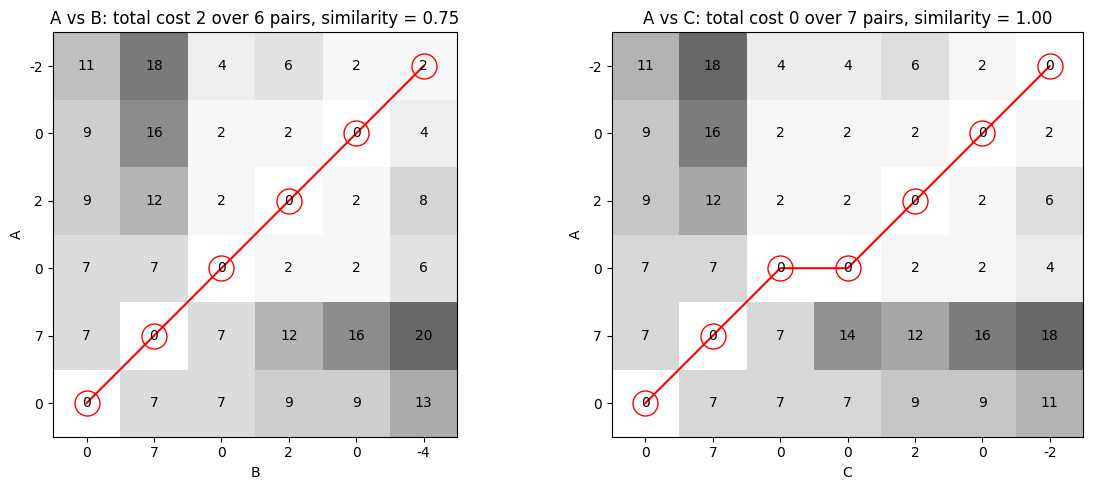

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, other, name in [(axes[0], B, "B"), (axes[1], C, "C")]:
    D = accumulated_cost(cost_matrix(A, other))
    P = optimal_path(D)

    ax.imshow(D, origin="lower", cmap="Greys", vmax=D.max() * 1.5)

    for (n, m), v in np.ndenumerate(D):
        ax.text(m, n, f"{v:g}", ha="center", va="center")

    ax.plot([m for n, m in P], [n for n, m in P], color="red", marker="o", markersize=18, markerfacecolor="none")

    ax.set_xticks(range(len(other)), other)
    ax.set_yticks(range(len(A)), A)
    ax.set_xlabel(name)
    ax.set_ylabel("A")
    ax.set_title(f"A vs {name}: total cost {D[-1, -1]:g} over {len(P)} pairs, "f"similarity = {dtw_similarity(A, other):.2f}")

plt.tight_layout()
plt.show()

Each cell holds the cheapest total cost of aligning the two melodies up to that point, and the red path is the optimal alignment, traced back from the last cell. Against `B`, the path is a straight diagonal, and the changed last step (−4 instead of −2) adds a cost of 2 at the end. Against `C`, the path moves sideways at the extra repeated note, pairing `A`’s 0 with both zeros in `C`, so the total cost stays 0. Edit distance treats both differences the same (distance 1), while DTW penalizes the changed note by how different it is and does not penalize the repetition at all.

#### 2.2.3 N-gram overlap

An n-gram is a run of $n$ consecutive elements. We take all overlapping n-grams (in our case we use $n = 3$) of each melody as a set and compare the sets using the Jaccard index:

$$\mathrm{sim}_\mathrm{ngram}(a, b) = \frac{|G(a) \cap G(b)|}{|G(a) \cup G(b)|}$$

where $G(x)$ is the set of n-grams of melody $x$.

In [8]:
n = 3
GA, GB = ngrams(A, n), ngrams(B, n)

print(f"{n}-grams of A: ", GA)
print(f"{n}-grams of B: ", GB)
print(f"Shared: {len(GA & GB)}")
print(f"Distinct: {len(GA | GB)}")
print(f"Similarity (Jaccard index): {ngram_similarity(A, B):.2f}")

3-grams of A:  {(7, 0, 2), (0, 2, 0), (2, 0, -2), (0, 7, 0)}
3-grams of B:  {(7, 0, 2), (2, 0, -4), (0, 2, 0), (0, 7, 0)}
Shared: 3
Distinct: 5
Similarity (Jaccard index): 0.60


N-grams ignore where in the melody a fragment occurs, so reordered phrases or an extra verse still leave most fragments shared. Within a fragment, however, everything must match exactly, and one changed note can break up to $n$ n-grams. Since sets are used, repeated fragments only count once. We have chosen $n = 3$ as a compromise, since shorter fragments would likely be too frequent across all melodies, while longer ones likely would be too rare.

#### 2.2.4 Durations

With durations, each element is a tuple `(value, duration)`. Edit distance and n-grams compare these tuples for exact equality, so durations make matching stricter, i.e. two notes will only match if both value and duration agree. Our implementation of DTW, on the other hand, uses the L1 (Manhattan) distance between the tuples, $|\Delta \mathrm{value}| + |\Delta \mathrm{duration}|$, which weights one semitone the same as a quarter note. This equal weighting is an arbitrary choice that we did not tune, and it gives durations relatively more influence for contour (values between −1 and +1) than for pitch and interval.

#### 2.2.5 Similarity matrices

`similarity_matrix(sequences, sim_fn)` computes the similarity between all pairs of the 360 melodies in the dataset. All three measures are symmetric, so as an optimization, only half of the matrix is computed and then mirrored. The script `src/run_distances` runs every representation × measure combination and saves each matrix as `results/<representation>_<measure>.npz`, together with the melody IDs in row order.

### 2.3 CLaMP 2

The hand-crafted methods compare melodies through features we chose ourselves. CLaMP 2 takes the opposite approach, it is a model pretrained on large collections of symbolic music that maps each melody to a fixed-length vector (*embedding*). Two melodies are considered similar if their embeddings point in a similar direction.

#### 2.3.1 From MIDI to embedding

1. **MIDI → MTF.** Each MIDI file is converted to MTF (MIDI Text Format), where every MIDI message becomes a line of text. Note numbers are kept as they are, so MTF encodes **absolute pitch**.
2. **MTF → embedding.** CLaMP 2's music encoder reads the text and produces one 768-dimensional vector per melody.
3. **Cosine similarity** between all pairs of embeddings gives a 360 × 360 matrix, in the same format as the hand-crafted methods:

$$\mathrm{sim}(i, j) = \frac{e_i \cdot e_j}{\|e_i\|\,\|e_j\|}$$


#### 2.3.2 Centering

The raw embeddings share a large common component, so every pair of melodies looks very similar and all similarities are squeezed into a narrow range near 1. To remove this shared part, we subtract the mean embedding of the 360 melodies before computing the cosine:

$$\tilde{e}_i = e_i - \frac{1}{N}\sum_{j=1}^{N} e_j$$

Centering uses no tune-family labels. We keep both versions: `clamp2_cosine` (raw) and `clamp2_cosine_centered`, which we use as the main CLaMP 2 result.

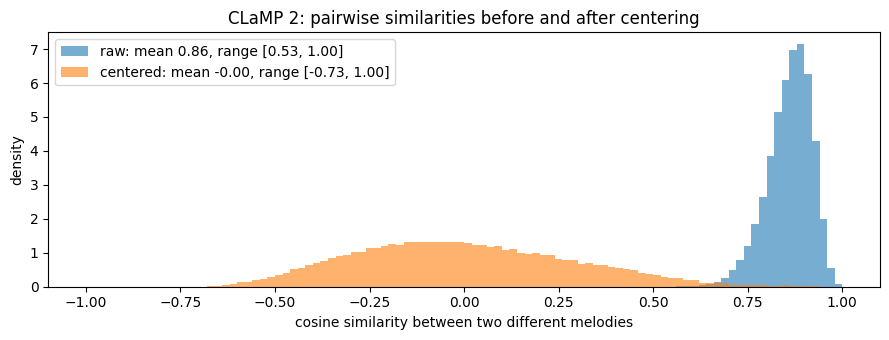

In [9]:
def load_sim(name):
    """Load a similarity matrix and its song ids from results/<name>.npz."""
    d = np.load(RESULTS / f"{name}.npz")
    return d["sim"], [str(i) for i in d["ids"]]

fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.linspace(-1, 1, 101)

for name, label in [("clamp2_cosine", "raw"), ("clamp2_cosine_centered", "centered")]:
    S, ids = load_sim(name)
    assert S.shape == (360, 360) and np.allclose(S, S.T)
    off_diag = S[~np.eye(len(S), dtype=bool)]  # exclude self-similarity
    ax.hist(off_diag, bins=bins, density=True, alpha=0.6,
            label=f"{label}: mean {off_diag.mean():.2f}, range [{off_diag.min():.2f}, {off_diag.max():.2f}]")

ax.set_xlabel("cosine similarity between two different melodies")
ax.set_ylabel("density")
ax.set_title("CLaMP 2: pairwise similarities before and after centering")
ax.legend()
plt.tight_layout()
plt.show()

Before centering, almost all similarities lie between 0.75 and 1, showing that every melody looks alike to the model. After centering, they spread from −1 to 1, which makes related and unrelated melodies easier to separate. The effect on MAP is shown in Section 3.

### 2.4 Evaluation (MAP)

All methods are evaluated in the same way. Each of the 360 melodies is used once as a query, and the other 359 melodies are ranked by their similarity to it. A result is relevant if it belongs to the same tune family as the query.

**Average precision (AP)** scores one ranking. At each position $k$ where a relevant melody appears, we compute the precision $P(k)$, the fraction of the top $k$ results that are relevant, and average these values:

$$\mathrm{AP}(q) = \frac{1}{R_q} \sum_{k=1}^{N - 1} P(k)\,\mathrm{rel}(k)$$

where $R_q$ is the number of relevant melodies for query $q$ and $\mathrm{rel}(k)$ is 1 if the result at position $k$ is relevant and 0 otherwise. AP is 1 when all relevant melodies are ranked first, and it drops when they appear further down the list.

**Mean average precision (MAP)** is the average AP over all 360 queries and summarizes each method in a single number between 0 and 1. As a reference, a random ranking gives a MAP of about 0.05.

As an example, take a query with three relevant melodies, found at positions 1, 3 and 4:

In [10]:
relevant = np.array([1, 0, 1, 1, 0, 0])  # 1 = same tune family as the query

precision_at_k = np.cumsum(relevant) / np.arange(1, len(relevant) + 1)
ap = precision_at_k[relevant == 1].mean()

print("precision at relevant positions:", np.round(precision_at_k[relevant == 1], 3))
print(f"AP = {ap:.3f}")

precision at relevant positions: [1.    0.667 0.75 ]
AP = 0.806


The AP of every query is stored in `results/figures/<method>_ap.csv` (columns `songid`, `tunefamily`, `ap`), which is used for the per-family analysis in Section 3.

## 3. Results

We first compare overall MAP for all methods (3.1), then look at how performance varies between tune families (3.2-3.3), and finally at the effect of adding durations (3.4). As reference points, a random ranking gives MAP 0.053.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

representations = [
    "pitch", "pitch+dur",
    "interval", "interval+dur",
    "contour", "contour+dur",
]
methods = ["ngram3", "edit", "dtw"]

frames = []
clamp_results = {}

map_table = pd.DataFrame(
    index=representations,
    columns=methods,
    dtype=float,
)

for path in ap_files:
    df = pd.read_csv(path)
    name = path.stem.removesuffix("_ap")

    df["model"] = name # Keep individual AP scores for the tune family analysis.
    frames.append(df)

    map_score = df["ap"].mean() # Calculate MAP for the overall comparisons.

    if name.startswith("clamp2_"):
        clamp_results[name] = map_score
    else:
        representation, method = name.rsplit("_", 1)
        map_table.loc[representation, method] = map_score

all_ap = pd.concat(frames, ignore_index=True)

clamp_table = pd.DataFrame.from_dict(
    clamp_results,
    orient="index",
    columns=["MAP"],
).rename(index={
    "clamp2_cosine": "CLaMP 2 — cosine",
    "clamp2_cosine_centered": "CLaMP 2 — centered cosine",
})

###3.1 Overall MAP heatmaps

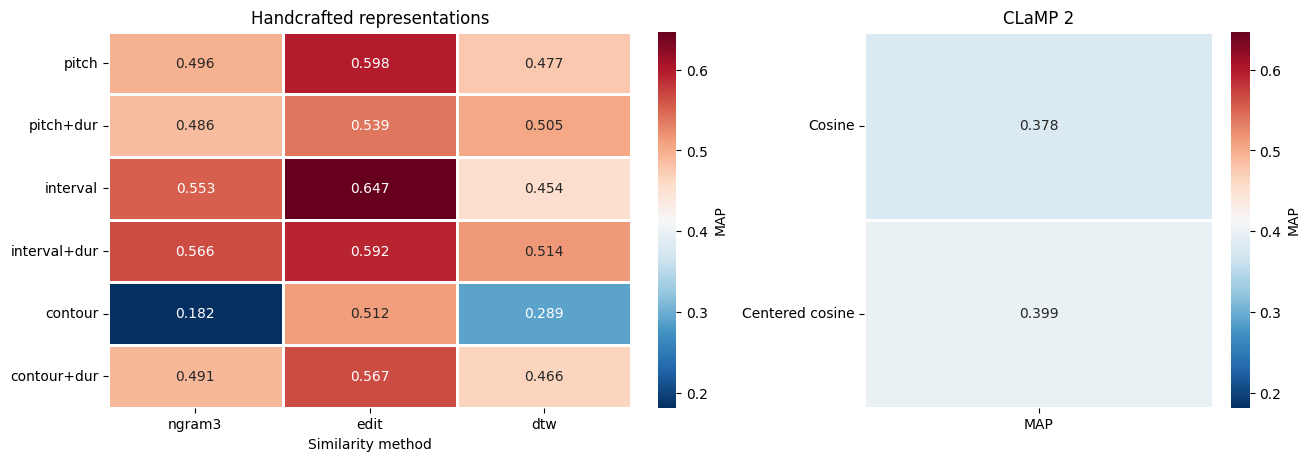

In [12]:
handcrafted = map_table.astype(float)
clamp = clamp_table.astype(float).rename(index={
    "CLaMP 2 — cosine": "Cosine",
    "CLaMP 2 — centered cosine": "Centered cosine",
})

vmin = min(handcrafted.min().min(), clamp.min().min())
vmax = max(handcrafted.max().max(), clamp.max().max())

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5),
    gridspec_kw={"width_ratios": [3, 2]},
    layout="constrained",
)

for ax, data, title in zip(
    axes,
    [handcrafted, clamp],
    ["Handcrafted representations", "CLaMP 2"],
):
    sns.heatmap(
        data,
        annot=True,
        fmt=".3f",
        cmap="RdBu_r",
        vmin=vmin,
        vmax=vmax,
        linewidths=1,
        cbar_kws={"label": "MAP"},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelrotation=0)

axes[0].set_xlabel("Similarity method")
axes[1].set_xlabel("")

plt.show()

These compare overall retrieval performance across the 18 handcrafted configurations and the two CLaMP 2 variants. Each value is the mean AP across all evaluated songs. Higher values indicate better retrieval. Both heatmaps share the same color scale: blue indicates lower scores and red higher scores.

All 18 hand-crafted methods perform far above a random ranking (MAP 0.053), and 16 of them outperform CLaMP 2 (0.399 with centering). Edit distance is the best measure for every representation, while DTW is the weakest in most cases. Among representations, intervals perform best, as expected, but pitch comes surprisingly close (0.598 vs 0.647 with edit distance), suggesting that many variants are already notated in the same key. Contour is the weakest representation, and contour with 3-grams fails almost completely (0.182). With only three possible values, there are just 27 possible 3-grams, so many melodies likely contain the same 3-grams which makes it difficult for the Jaccard index to tell them apart.

###3.2 Configuration by family heatmap

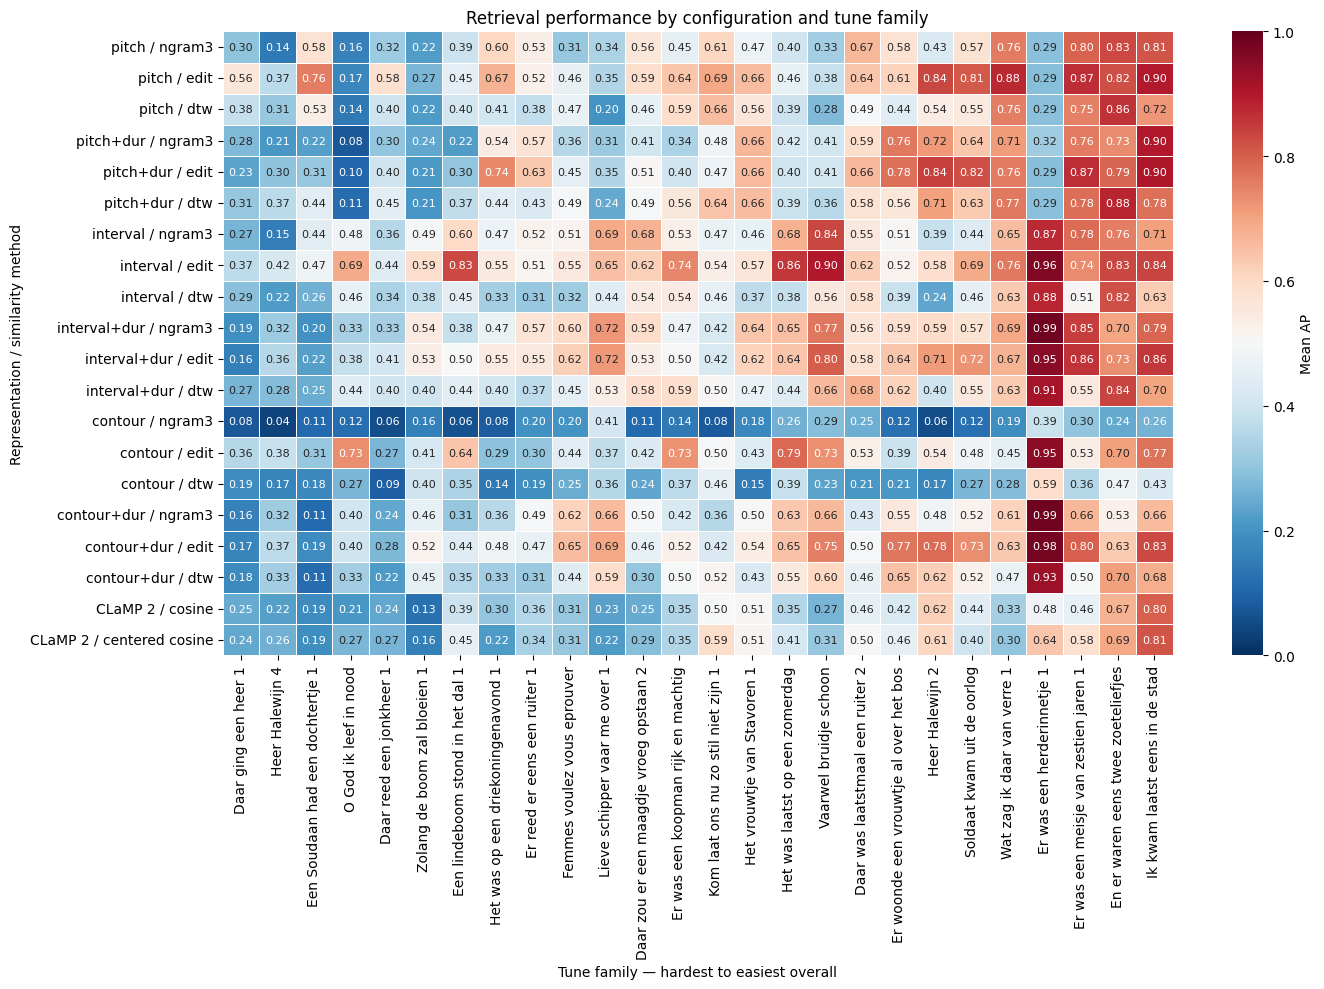

In [13]:
representations = [
    "pitch", "pitch+dur",
    "interval", "interval+dur",
    "contour", "contour+dur",
]
methods = ["ngram3", "edit", "dtw"]

model_order = [
    f"{representation}_{method}"
    for representation in representations
    for method in methods
]

model_order += [
    "clamp2_cosine",
    "clamp2_cosine_centered",
]

family_matrix = (
    all_ap[all_ap["model"].isin(model_order)]
    .pivot_table(
        index="model",
        columns="tunefamily",
        values="ap",
        aggfunc="mean",
    )
    .reindex(model_order)
)

family_order = family_matrix.mean(axis=0).sort_values().index
family_matrix = family_matrix[family_order]

plt.figure(figsize=(max(14, len(family_matrix.columns) * 0.55), 10))

ax = sns.heatmap(
    family_matrix,
    cmap="RdBu_r",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 8},
    linewidths=0.5,
    cbar_kws={"label": "Mean AP"},
)

display_names = {
    "clamp2_cosine": "CLaMP 2 / cosine",
    "clamp2_cosine_centered": "CLaMP 2 / centered cosine",
}

ax.set_yticklabels([
    display_names.get(name, name.replace("_", " / "))
    for name in family_matrix.index
], rotation=0)

ax.set_xticklabels([
    name.replace("_", " ")
    for name in family_matrix.columns
], rotation=90)

ax.set_xlabel("Tune family — hardest to easiest overall")
ax.set_ylabel("Representation / similarity method")
ax.set_title("Retrieval performance by configuration and tune family")

plt.tight_layout()
plt.show()

Each cell shows the average AP for one tune family under one configuration. Reading down a column reveals which configurations work best for that family and reading across a row shows which families a configuration handles well. Families are ordered from hardest to easiest based on their average across all 20 configurations.

We can see that performance varies much more between tune families than between methods. Some families are retrieved almost perfectly by most methods, while others are hard for all of them.

The family “Er was een herderinnetje 1” is a clear example of the effect of representation. With intervals and contour, its AP is mostly in the range 0.87-0.99, but with pitch it stays around 0.29 regardless of the distance measure. This is the pattern expected if its variants are notated in different keys, where pitch sees transposed variants as different, while intervals and contour are unaffected. It is also the family that gained most from centering in CLaMP 2. The opposite occurs for “Heer Halewijn 2”, which is retrieved better with pitch (0.84 with edit distance) than with intervals and edit distance (0.58), suggesting that absolute pitch can also carry useful information when variants share a key.

CLaMP 2 shows a flatter profile. It is rarely the best method for any family, and it struggles with several families that intervals with edit distance handle well.

###3.3 Easiest and hardest tune families to predict


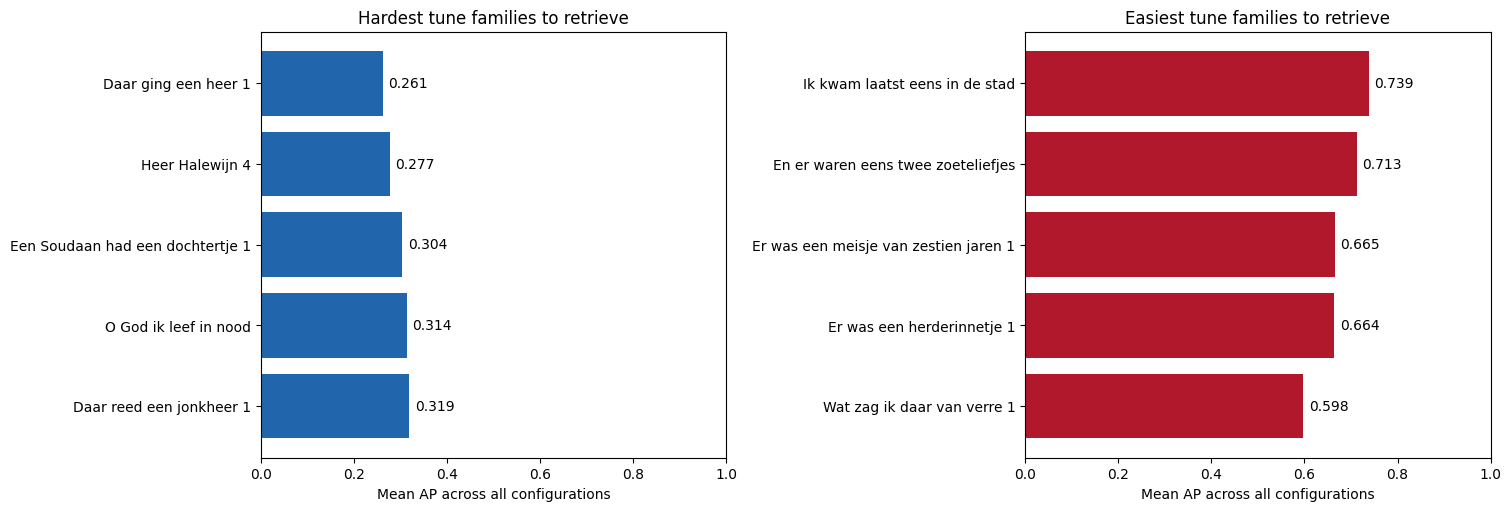

In [14]:
family_scores = (
    all_ap.groupby("tunefamily")["ap"]
    .mean()
    .sort_values()
)

hardest = family_scores.head(5)
easiest = family_scores.tail(5).sort_values(ascending=False)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    layout="constrained",
)

for ax, scores, title, color in [
    (axes[0], hardest, "Hardest tune families to retrieve", "#2166ac"),
    (axes[1], easiest, "Easiest tune families to retrieve", "#b2182b"),
]:
    labels = scores.index.str.replace("_", " ")

    bars = ax.barh(labels, scores.values, color=color)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Mean AP across all configurations")
    ax.set_title(title)
    ax.bar_label(bars, fmt="%.3f", padding=4)

plt.show()

These show the five families with the lowest and highest average AP across their songs and all configurations. They indicate which families are generally harder or easier to retrieve using the tested methods.

The hardest families, such as “Daar ging een heer 1” (0.261) and “Heer Halewijn 4” (0.277), are hard for every method, which suggests that their variants differ more from each other than in other families, or that they resemble other families. The easiest, such as “Ik kwam laatst eens in de stad” (0.739), are retrieved well even by CLaMP 2 (0.81 centered), indicating that its variants stay close to each other in both pitch and rhythm.

###3.4 Duration impact

In [15]:
rows = []

for representation in ["pitch", "interval", "contour"]:
    for method in ["ngram3", "edit", "dtw"]:
        without = map_table.loc[representation, method]
        with_duration = map_table.loc[f"{representation}+dur", method]

        rows.append({
            "Representation": representation,
            "Method": method,
            "Without duration": without,
            "With duration": with_duration,
            "ΔMAP": with_duration - without,
        })

duration_effect = pd.DataFrame(rows).set_index(
    ["Representation", "Method"]
)

display(
    duration_effect.style.format({
        "Without duration": "{:.3f}",
        "With duration": "{:.3f}",
        "ΔMAP": "{:+.3f}",
    })
)

This compares each handcrafted representation and similarity method with and without duration information. ΔMAP = MAP with duration − MAP without duration: positive values indicate improvement while negative values indicate a decrease. For example, +0.025 means an increase of 0.025 MAP, or 2.5 percentage points.

Durations have opposite effects depending on the representation and measure. For contour, they help with all three measures, most strongly for 3-grams (+0.309) and DTW (+0.176). For pitch and interval with edit distance, durations instead hurt (−0.058 and −0.055). DTW improves with durations for all representations.

## 4. Discussion and future work

After showing the results of each method in Section 3, we will discuss and compare the results with our expectations, and point out what limits our conclusions.

### 4.1 Representations

As expected, intervals gave the best results, with the highest MAP for edit distance (0.647). However, pitch came surprisingly close (0.598). Section 3.2 helps to explain this: for most families the two representations perform similarly, and the large differences appear in a few families, such as "Er was een herderinnetje 1", where pitch fails while intervals and contour work well. This suggests that robustness to transposition does not matter much on average, but it is decisive for the families with variants in different keys. Families such as "Heer Halewijn 2" also show that absolute pitch can be useful when the variants share a key. Contour was, as expected, the weakest representation, since it loses too much information to separate unrelated melodies, especially when combined with 3-grams (0.182).

### 4.2 Distance measures

Edit distance was the best measure for every representation. Our interpretation is that variants of the same tune in MTC-ANN mostly differ by local changes, i.e. a note that is added, removed or changed, which is exactly what edit distance counts. DTW was the weakest measure in most cases. Since it can pair one note with several notes in the other melody, repeated or long notes do not add any cost, which may make it too flexible when durations are not included. This is supported by Section 3.4, where adding durations improves DTW for all three representations.

### 4.3 Durations

Durations can either help or hurt depending on the representation. For edit distance and n-grams, durations make matching stricter, since two notes only match if both the value and the duration are the same. For pitch and intervals, which already contain enough information, this hurts (−0.06 with edit distance), possibly because variants of the same tune differ in rhythm. For contour, which contains very little information on its own, durations add the missing information, and with 3-grams the MAP increases from 0.182 to 0.491. Furthermore, contour with durations and edit distance (0.567) comes close to intervals with durations (0.592), which suggests that once rhythm is included, the exact size of each step does not add much.

### 4.4 CLaMP 2

We expected the pretrained model to capture similarities that our hand-crafted methods might miss, but it performed below 16 of the 18 hand-crafted methods (0.399 with centering). There are several possible reasons for this. CLaMP 2 was not trained for tune-family retrieval, and it describes a whole melody with a single vector. Before centering, all melodies were very similar to each other (Section 2.3.2), which suggests that the embeddings mostly capture what the melodies in the dataset have in common rather than what separates the families. Moreover, MTF keeps absolute pitch, and CLaMP 2 performs much worse than intervals on "Er was een herderinnetje 1" (0.64 vs 0.96), the same family where pitch fails. Finally, we used the model without any adaptation to this task, so the results show how well general embeddings work directly, not the full potential of the model.

### 4.5 Limitations and future work

Our conclusions are limited in several ways:

- We only tested one n-gram length ($n = 3$), and the weighting between pitch and duration in DTW was not tuned.
- Rests are not represented.
- MTC-ANN is a small dataset with 26 families of 8-27 melodies each, so the AP of a single family depends on very few queries.
- CLaMP 2 was pretrained on large collections of symbolic music, so some of our melodies could have been seen during pretraining.

For future work, rests could be included in the representations, and durations could be compared less strictly, so that small rhythmic differences between variants are not penalized as much. Other n-gram lengths and duration weights in DTW could also be tested. For CLaMP 2, a first test where the melodies were transposed to the common key of their family using the expert annotations increased MAP from 0.399 to 0.482 (see `docs/clamp2.md`). A next step would be to estimate the key automatically, or to adapt the model to the task, for example by training a simple classifier on the embeddings. Finally, the evaluation could be repeated on a larger dataset to get more reliable results per family.

---
### Statement on Generative AI Use

During this project, we used large language models (LLMs) as a support tool. We used them to assist with the code, mainly for debugging, writing helper functions and producing the plotting code for the figures. We also used them to discuss possible interpretations of some of our results. Any explanation we kept was checked against our own data before being included. Finally, LLMs helped us generate a first draft of the presentation slides, which we then reviewed and edited ourselves. The research question, the choice of methods, the experiments and the conclusions are our own. We take full responsibility for the content of this report and consider this use of LLMs fair and in line with the course guidelines.